In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/train.csv")

In [4]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


Всего имеем 11 колонок в датасете: одна из них это технический айдишник (PassengerId), другая это таргет (Survived), то есть 9 остальных колонок это наши полезные фичи для модели

И не все из них полезны в сыром виде: Name это по сути бесполезная фича для модели, НО можно извлечь оттуда Title в качестве отдельной фичи, это уже потенциально полезно

Аналогично Ticket звучит как бесполезная фича для модели, но можно посмотреть на пассажиров, у которых ticket одинаковый, скорее всего это родственники / друзья

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Тут можем наблюдать некоторые статистики (далеко не все из них осмысленные)

Из полезных: средний возраст - 29 лет, средняя цена билета - 32 (доллара полагаю)

In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Ниже видим, что в колонках Age, Cabin и Embarked есть пропуски, в Embarked они минорные (всего 2), а в Age и Cabin их существенно больше, придется их обрабатывать

In [7]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Добавим некоторые по смыслу напрашивающиеся фичи в датасет
1)

In [8]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1 # Это числовая фича, которая показывает сколько в семье человек (+1 на самого человека)
df["HasFamily"] = (df["SibSp"] + df["Parch"] > 0).astype(int) # Бинарная фича, которая показывает был ли человек один

df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")[0].str.strip() # Категориальная фича, достаем Title из имени человека (Mr / Ms / Mrs / Master)

# Создаем конкретные возрастные бакеты для людей
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 18, 35, 55, np.inf],
    labels=["kid", "young_adult", "adult", "senior"],
    right=False,
)

df["AgeGroup"] = df["AgeGroup"].astype("object").fillna("Unknown")

In [10]:
# Редкие тайтлы можно заменить в один other_title (Всех, кто меньше Master'a по значениям)
df["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [12]:
# Тут создаем фичу есть ли у человека кабина, и в целом вытаскиваем конкретный отсек в переменную Deck
df["HasCabin"] = df["Cabin"].notna().astype(int)
df["Deck"] = df["Cabin"].str[0].fillna("Unknown")

In [13]:
df["TicketGroupSize"] = df.groupby("Ticket")["Ticket"].transform("size")

Теперь исследуем связь таргета с другими фичами

In [16]:
def plot_survival_rate(df, feature):
    summary = (
        df.groupby(feature, dropna=False)["Survived"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "survival_rate"})
    )

    print(summary)

    summary["survival_rate"].plot(kind="bar", figsize=(8, 4))
    plt.title(f"Survival Rate by {feature}")
    plt.ylabel("Survival Rate")
    plt.xlabel(feature)
    plt.ylim(0, 1)
    plt.xticks(rotation=0)
    plt.show()

Тут в целом можно сделать выводы, что женщины в среднем выживали больше, чем мужчины, а также что класс пассажира (1 > 2 > 3) тоже определял долю выживших достаточно сильно

Среди детей как возрастной группы тоже выживших было больше всего в процентном соотношении, а вот делать какие-то выводы по наличию жен/мужей и детей/сестер тут не стоит, потому что сильно перемешаны correlation & causation

        survival_rate  count
Sex                         
female       0.742038    314
male         0.188908    577


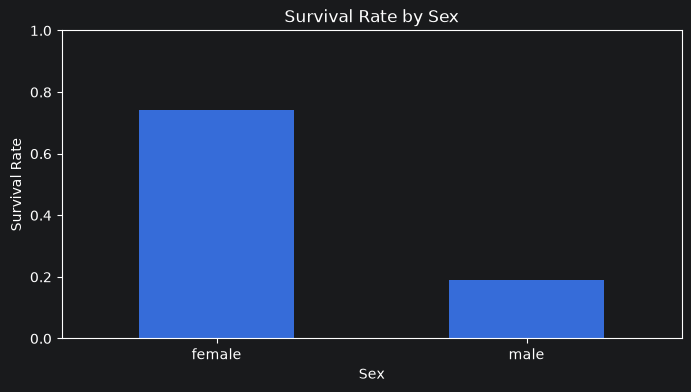

        survival_rate  count
Pclass                      
1            0.629630    216
2            0.472826    184
3            0.242363    491


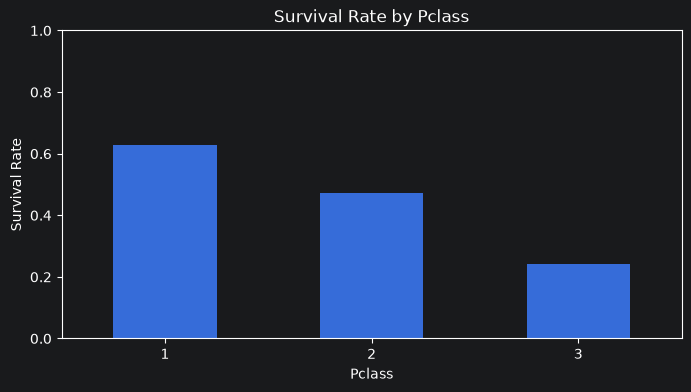

             survival_rate  count
AgeGroup                         
Unknown           0.293785    177
adult             0.419689    193
kid               0.539823    113
senior            0.309524     42
young_adult       0.368852    366


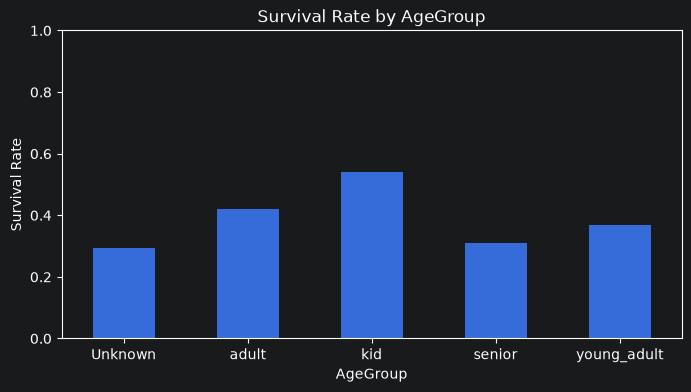

       survival_rate  count
SibSp                      
0           0.345395    608
1           0.535885    209
2           0.464286     28
3           0.250000     16
4           0.166667     18
5           0.000000      5
8           0.000000      7


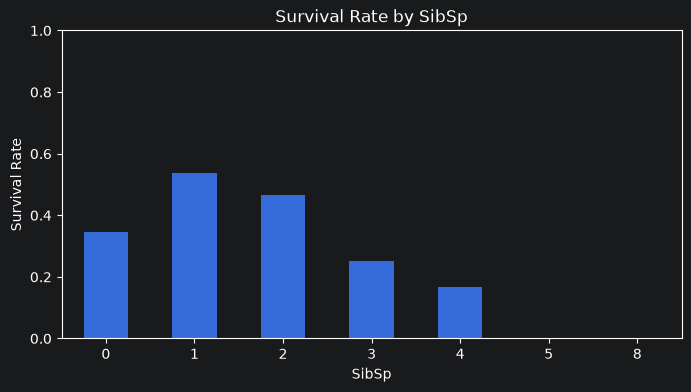

       survival_rate  count
Parch                      
0           0.343658    678
1           0.550847    118
2           0.500000     80
3           0.600000      5
4           0.000000      4
5           0.200000      5
6           0.000000      1


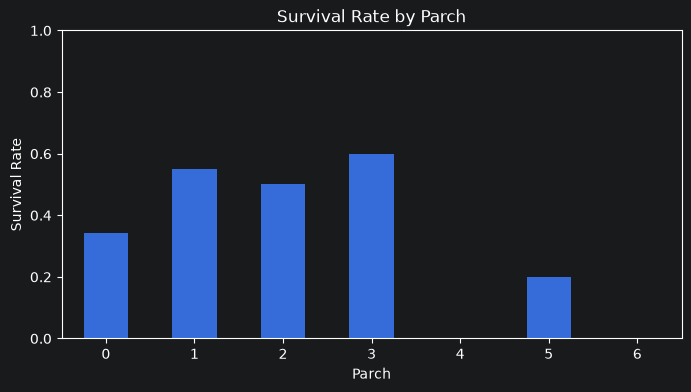

In [17]:
plot_survival_rate(df, "Sex")
plot_survival_rate(df, "Pclass")
plot_survival_rate(df, "AgeGroup")
plot_survival_rate(df, "SibSp")
plot_survival_rate(df, "Parch")

Тут тоже видим интересную статистику, в частности Survival Rate by Title: есть очень редкие тайтлы, которые встретились пару раз за весь датасет, и их владельцы выжили (например графиня) и они не очень репрезентативны конечно же в силу закона малых чисел

           survival_rate  count
HasFamily                      
0               0.303538    537
1               0.505650    354


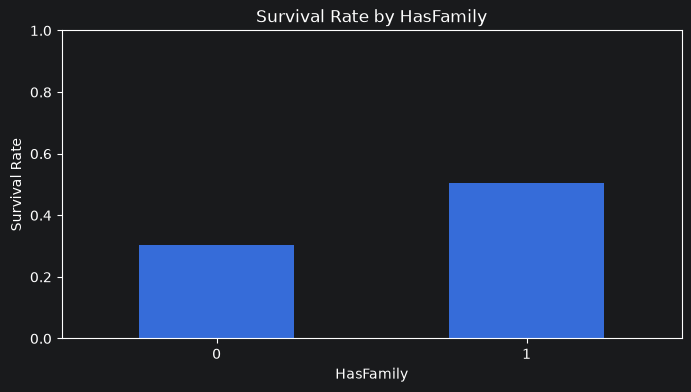

            survival_rate  count
FamilySize                      
1                0.303538    537
2                0.552795    161
3                0.578431    102
4                0.724138     29
5                0.200000     15
6                0.136364     22
7                0.333333     12
8                0.000000      6
11               0.000000      7


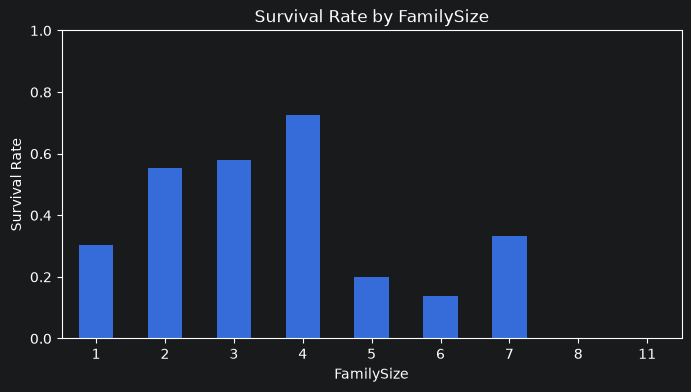

          survival_rate  count
Embarked                      
C              0.553571    168
Q              0.389610     77
S              0.336957    644
NaN            1.000000      2


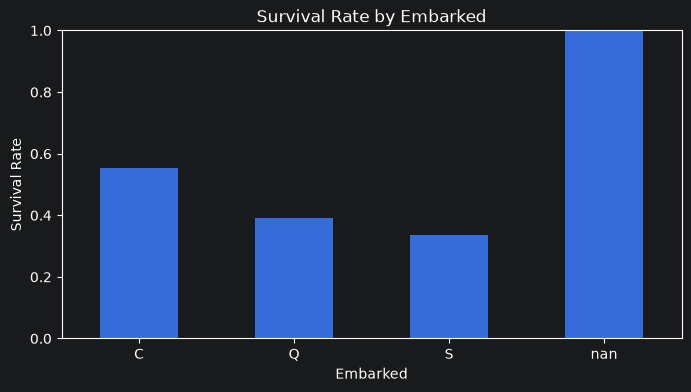

              survival_rate  count
Title                             
Capt               0.000000      1
Col                0.500000      2
Don                0.000000      1
Dr                 0.428571      7
Jonkheer           0.000000      1
Lady               1.000000      1
Major              0.500000      2
Master             0.575000     40
Miss               0.697802    182
Mlle               1.000000      2
Mme                1.000000      1
Mr                 0.156673    517
Mrs                0.792000    125
Ms                 1.000000      1
Rev                0.000000      6
Sir                1.000000      1
the Countess       1.000000      1


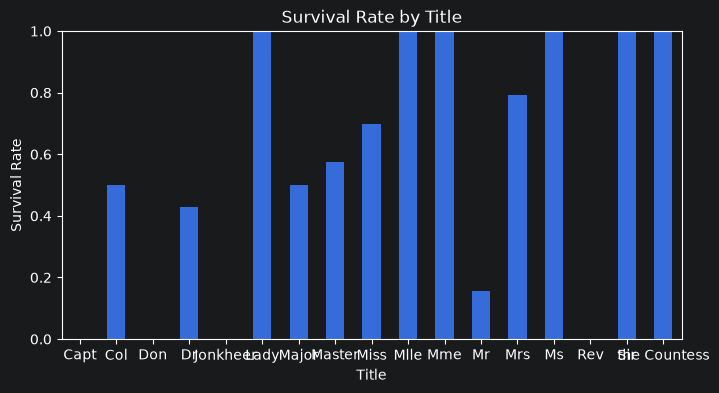

         survival_rate  count
Deck                         
A             0.466667     15
B             0.744681     47
C             0.593220     59
D             0.757576     33
E             0.750000     32
F             0.615385     13
G             0.500000      4
T             0.000000      1
Unknown       0.299854    687


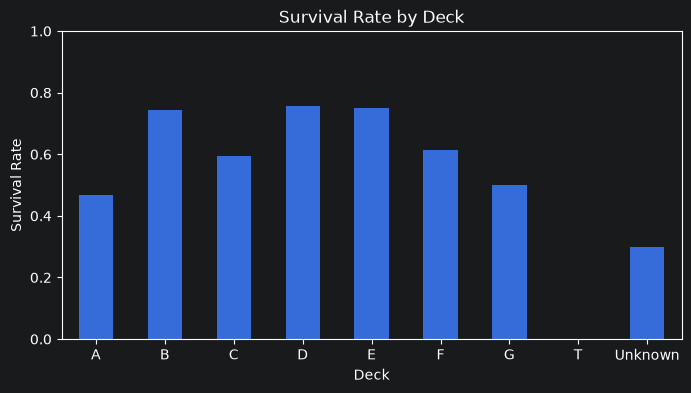

          survival_rate  count
HasCabin                      
0              0.299854    687
1              0.666667    204


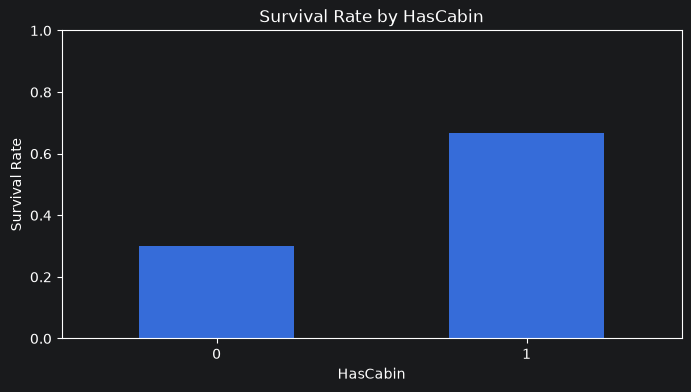

In [18]:
plot_survival_rate(df, "HasFamily")
plot_survival_rate(df, "FamilySize")
plot_survival_rate(df, "Embarked")
plot_survival_rate(df, "Title")
plot_survival_rate(df, "Deck")
plot_survival_rate(df, "HasCabin")

Тут можем заметить, что больше всего выживало женщин из первого класса, а меньше всего - мужчин из третьего (логично)

Но даже тут видно, что женщин из третьего класса выживало больше, чем мужчин из первого

In [19]:
pd.crosstab(
    [df["Sex"], df["Pclass"]],
    df["Survived"],
    normalize="index",
)

Survived              0         1
Sex    Pclass                    
female 1       0.031915  0.968085
       2       0.078947  0.921053
       3       0.500000  0.500000
male   1       0.631148  0.368852
       2       0.842593  0.157407
       3       0.864553  0.135447

Распределение таргета по AgeGroup x Sex


In [20]:
pd.crosstab(
    [df["Sex"], df["AgeGroup"]],
    df["Survived"],
    normalize="index",
)

Survived                   0         1
Sex    AgeGroup                       
female Unknown      0.320755  0.679245
       adult        0.211268  0.788732
       kid          0.309091  0.690909
       senior       0.100000  0.900000
       young_adult  0.248000  0.752000
male   Unknown      0.870968  0.129032
       adult        0.795082  0.204918
       kid          0.603448  0.396552
       senior       0.875000  0.125000
       young_adult  0.829876  0.170124

В целом значения таргета довольно сбалансированы (не 50/50 конечно, но ~60/40 тоже гуд)

In [21]:
target_counts = df["Survived"].value_counts()
target_share = df["Survived"].value_counts(normalize=True)

print(target_counts)
print(target_share)

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


Посмотрим корреляцию числовых фичей между собой и с таргетом

In [22]:
numeric_columns = [
    "Survived",
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "HasFamily",
    "HasCabin",
]

correlation_matrix = df[numeric_columns].corr()

correlation_matrix

,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,HasFamily,HasCabin
Survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307,0.016639,0.203367,0.316912
Pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500,0.065997,-0.135207,-0.725541
Age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067,-0.301914,-0.198270,0.249732
SibSp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651,0.890712,0.584471,-0.040460
Parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225,0.783111,0.583398,0.036987
Fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000,0.217138,0.271832,0.482075
FamilySize,0.016639,0.065997,-0.301914,0.890712,0.783111,0.217138,1.000000,0.690922,-0.009175
HasFamily,0.203367,-0.135207,-0.198270,0.584471,0.583398,0.271832,0.690922,1.000000,0.158029
HasCabin,0.316912,-0.725541,0.249732,-0.040460,0.036987,0.482075,-0.009175,0.158029,1.000000


Видим тут позитивно и негативно коррелирующие с таргетом числовые фичи, это поможет в будущем с интерпретируемостью модели

In [23]:
correlation_matrix["Survived"].sort_values(ascending=False)

Survived      1.000000
HasCabin      0.316912
Fare          0.257307
HasFamily     0.203367
Parch         0.081629
FamilySize    0.016639
SibSp        -0.035322
Age          -0.077221
Pclass       -0.338481
Name: Survived, dtype: float64

На этом EDA закрываю, в целом уже есть представление о датасете, его фичах, какие новые фичи нужно создать, какие старые неинформативные нужно дропнуть и как в целом подойти к пайплайну